In [3]:
#data inspection 



/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/09_20__walk_down_hall_angry__MKEWB4SM.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/Deepfakes/424_408.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/Face2Face/125_038.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/FaceShifter/858_861.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/FaceSwap/471_455.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/NeuralTextures/776_676.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/csv/FF++_Metadata_Shuffled.csv


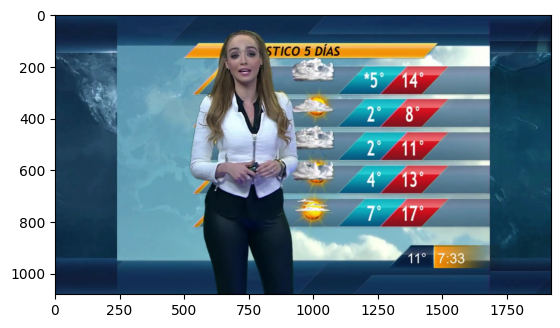

In [4]:
import os
import cv2 as cv
import random
import matplotlib.pyplot as plt

dir_path ="/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23"

for i in os.listdir(dir_path):
    folder_path = os.path.join(dir_path, i)

    if os.path.isdir(folder_path):
        files = os.listdir(folder_path)

        if len(files) > 0:
            n = random.randint(0, len(files) - 1)
            path = os.path.join(folder_path, files[n])

            print(path)
            vid=cv.VideoCapture(path)
            bool, frame = vid.read()
            if not bool:
                break

            plt.imshow(cv.cvtColor(frame,cv.COLOR_BGR2RGB))



In [5]:
import os
import glob
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23"

# Find all metadata CSV files
csv_files = glob.glob(
    os.path.join(DATASET_PATH, "csv", "*.csv")
)

print("CSV files found:", len(csv_files))
for path in csv_files:
    print(os.path.basename(path))

# Load and combine metadata
dfs = []

for path in csv_files:
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    required = {"File Path", "Label"}
    if required.issubset(df.columns):
        dfs.append(df)

if not dfs:
    raise ValueError("No CSVs with File Path and Label columns found.")

manifest = pd.concat(dfs, ignore_index=True)

# Clean labels and paths
manifest["Label"] = manifest["Label"].astype(str).str.strip().str.upper()
manifest["File Path"] = manifest["File Path"].astype(str).str.strip()

# Convert labels to binary values
label_map = {"REAL": 0, "FAKE": 1}
manifest["label"] = manifest["Label"].map(label_map)

# Resolve paths against the dataset root
manifest["video_path"] = manifest["File Path"].apply(
    lambda p: os.path.normpath(os.path.join(DATASET_PATH, p))
)

# Check that each video exists
manifest["exists"] = manifest["video_path"].apply(os.path.isfile)

print("\nTotal rows:", len(manifest))
print("\nLabel counts:")
print(manifest["Label"].value_counts(dropna=False))

print("\nFiles found:", manifest["exists"].sum())
print("Files missing:", (~manifest["exists"]).sum())

manifest.head()

CSV files found: 10
DeepFakeDetection.csv
Deepfakes.csv
FF++_Metadata.csv
FF++_Metadata_Shuffled.csv
Face2Face.csv
FaceShifter.csv
FaceSwap.csv
Mean_Data.csv
NeuralTextures.csv
original.csv

Total rows: 21000

Label counts:
Label
FAKE    18000
REAL     3000
Name: count, dtype: int64

Files found: 21000
Files missing: 0


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB),label,video_path,exists
0,0,DeepFakeDetection/01_02__meeting_serious__YVGY...,FAKE,1044,1920,1080,h264,6.43,1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
1,1,DeepFakeDetection/01_02__outside_talking_still...,FAKE,727,1920,1080,h264,5.05,1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
2,2,DeepFakeDetection/01_02__talking_against_wall_...,FAKE,841,1920,1080,h264,3.31,1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
3,3,DeepFakeDetection/01_02__walk_down_hall_angry_...,FAKE,217,1920,1080,h264,1.11,1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
4,4,DeepFakeDetection/01_02__walking_down_indoor_h...,FAKE,773,1920,1080,h264,12.05,1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True


In [6]:
# Keep valid labels and existing videos
manifest = manifest[
    manifest["label"].notna() &
    manifest["exists"]
].copy()

manifest["label"] = manifest["label"].astype(int)

# Remove duplicate video paths
manifest = manifest.drop_duplicates(
    subset="video_path"
).reset_index(drop=True)

print("Valid unique videos:", len(manifest))
print("\nClass distribution:")
print(manifest["label"].value_counts().rename(
    index={0: "REAL", 1: "FAKE"}
))

print("\nExample rows:")
display(
    manifest[
        ["video_path", "Label", "label", "Frame Count", "Width", "Height"]
    ].head()
)

Valid unique videos: 7000

Class distribution:
label
FAKE    6000
REAL    1000
Name: count, dtype: int64

Example rows:


,video_path,Label,label,Frame Count,Width,Height
0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,FAKE,1,1044,1920,1080
1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,FAKE,1,727,1920,1080
2,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,FAKE,1,841,1920,1080
3,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,FAKE,1,217,1920,1080
4,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,FAKE,1,773,1920,1080


In [7]:
OUTPUT_PATH = "/kaggle/working/video_manifest.csv"

manifest.to_csv(OUTPUT_PATH, index=False)

print("Manifest saved to:", OUTPUT_PATH)

Manifest saved to: /kaggle/working/video_manifest.csv


In [8]:
# Inspect available metadata columns
print("Columns:")
print(manifest.columns.tolist())

# Inspect example filenames from each class
for label, name in [(0, "REAL"), (1, "FAKE")]:
    print(f"\n{name} examples:")
    paths = manifest.loc[
        manifest["label"] == label, "video_path"
    ].head(10)

    for path in paths:
        print(os.path.relpath(path, DATASET_PATH))

Columns:
['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)', 'label', 'video_path', 'exists']

REAL examples:
original/000.mp4
original/001.mp4
original/002.mp4
original/003.mp4
original/004.mp4
original/005.mp4
original/006.mp4
original/007.mp4
original/008.mp4
original/009.mp4

FAKE examples:
DeepFakeDetection/01_02__meeting_serious__YVGY8LOK.mp4
DeepFakeDetection/01_02__outside_talking_still_laughing__YVGY8LOK.mp4
DeepFakeDetection/01_02__talking_against_wall__YVGY8LOK.mp4
DeepFakeDetection/01_02__walk_down_hall_angry__YVGY8LOK.mp4
DeepFakeDetection/01_02__walking_down_indoor_hall_disgust__YVGY8LOK.mp4
DeepFakeDetection/01_03__hugging_happy__ISF9SP4G.mp4
DeepFakeDetection/01_03__kitchen_pan__JZUXXFRB.mp4
DeepFakeDetection/01_03__podium_speech_happy__480LQD1C.mp4
DeepFakeDetection/01_03__talking_against_wall__JZUXXFRB.mp4
DeepFakeDetection/01_04__hugging_happy__GBC7ZGDP.mp4


In [9]:
# Inspect metadata from each CSV
for csv_file in csv_files:
    df = pd.read_csv(csv_file)

    print("\nCSV:", os.path.basename(csv_file))
    print("Columns:", df.columns.tolist())
    display(df.head(3))


CSV: DeepFakeDetection.csv
Columns: ['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)']


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB)
0,0,DeepFakeDetection/01_02__meeting_serious__YVGY...,FAKE,1044,1920,1080,h264,6.43
1,1,DeepFakeDetection/01_02__outside_talking_still...,FAKE,727,1920,1080,h264,5.05
2,2,DeepFakeDetection/01_02__talking_against_wall_...,FAKE,841,1920,1080,h264,3.31



CSV: Deepfakes.csv
Columns: ['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)']


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB)
0,0,Deepfakes/000_003.mp4,FAKE,396,640,480,h264,0.85
1,1,Deepfakes/001_870.mp4,FAKE,460,1280,720,h264,2.74
2,2,Deepfakes/002_006.mp4,FAKE,693,1280,720,h264,1.98



CSV: FF++_Metadata.csv
Columns: ['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)']


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB)
0,0,DeepFakeDetection/01_02__meeting_serious__YVGY...,FAKE,1044,1920,1080,h264,6.43
1,1,DeepFakeDetection/01_02__outside_talking_still...,FAKE,727,1920,1080,h264,5.05
2,2,DeepFakeDetection/01_02__talking_against_wall_...,FAKE,841,1920,1080,h264,3.31


... (10 outputs left out)


CSV: NeuralTextures.csv
Columns: ['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)']


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB)
0,0,NeuralTextures/000_003.mp4,FAKE,303,640,480,h264,0.62
1,1,NeuralTextures/001_870.mp4,FAKE,460,1280,720,h264,2.71
2,2,NeuralTextures/002_006.mp4,FAKE,310,1280,720,h264,0.91



CSV: original.csv
Columns: ['Unnamed: 0', 'File Path', 'Label', 'Frame Count', 'Width', 'Height', 'Codec', 'File Size(MB)']


,Unnamed: 0,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB)
0,0,original/000.mp4,REAL,396,640,480,h264,0.85
1,1,original/001.mp4,REAL,460,1280,720,h264,2.78
2,2,original/002.mp4,REAL,693,1280,720,h264,2.02


In [10]:
#removing FF++_Metadata.csv and FF++_Metadata Shuffl.csv as they contain overlapping records frm the same dataset, so combining will make duplicates.
#updating the manifest 

In [11]:
import os
import glob
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23"
CSV_PATH = os.path.join(DATASET_PATH, "csv")

# Use only individual video metadata CSVs
metadata_files = [
    "original.csv",
    "Deepfakes.csv",
    "Face2Face.csv",
    "FaceShifter.csv",
    "FaceSwap.csv",
    "NeuralTextures.csv",
    "DeepFakeDetection.csv",
]

dfs = []

for filename in metadata_files:
    path = os.path.join(CSV_PATH, filename)

    if not os.path.exists(path):
        print("Missing CSV:", filename)
        continue

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    dfs.append(df)

manifest = pd.concat(dfs, ignore_index=True)

# Remove the CSV's saved index column
manifest = manifest.drop(
    columns=["Unnamed: 0"], errors="ignore"
)

# Convert labels to binary
manifest["Label"] = manifest["Label"].str.strip().str.upper()
manifest["label"] = manifest["Label"].map(
    {"REAL": 0, "FAKE": 1}
)

# Resolve paths
manifest["video_path"] = manifest["File Path"].apply(
    lambda p: os.path.normpath(
        os.path.join(DATASET_PATH, p)
    )
)

# Verify files
manifest["exists"] = manifest["video_path"].apply(
    os.path.isfile
)

# Keep valid, existing videos
manifest = manifest[
    manifest["label"].notna() & manifest["exists"]
].copy()

manifest = manifest.drop_duplicates(
    subset="video_path"
).reset_index(drop=True)

print("Total videos:", len(manifest))
print("\nClass distribution:")
print(manifest["Label"].value_counts())

print("\nVideos per folder:")
print(
    manifest["File Path"]
    .str.split("/")
    .str[0]
    .value_counts()
)

display(manifest.head())

Total videos: 7000

Class distribution:
Label
FAKE    6000
REAL    1000
Name: count, dtype: int64

Videos per folder:
File Path
original             1000
Deepfakes            1000
Face2Face            1000
FaceShifter          1000
FaceSwap             1000
NeuralTextures       1000
DeepFakeDetection    1000
Name: count, dtype: int64


,File Path,Label,Frame Count,Width,Height,Codec,File Size(MB),label,video_path,exists
0,original/000.mp4,REAL,396,640,480,h264,0.85,0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
1,original/001.mp4,REAL,460,1280,720,h264,2.78,0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
2,original/002.mp4,REAL,693,1280,720,h264,2.02,0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
3,original/003.mp4,REAL,303,640,480,h264,0.58,0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True
4,original/004.mp4,REAL,309,1280,720,h264,1.20,0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,True


In [12]:
#inspect the filename patterns and check whether our metadata includes source relationships

In [13]:
import os
import re

# Inspect fake-video filename patterns
fake_videos = manifest.loc[
    manifest["label"] == 1, "File Path"
]

for folder in manifest["File Path"].str.split("/").str[0].unique():
    print(f"\n{folder}:")
    examples = fake_videos[
        fake_videos.str.startswith(folder + "/")
    ].head(5)

    for path in examples:
        filename = os.path.basename(path)
        print(" ", filename)


original:

Deepfakes:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4

Face2Face:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4

FaceShifter:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4

FaceSwap:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4

NeuralTextures:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4

DeepFakeDetection:
  01_02__meeting_serious__YVGY8LOK.mp4
  01_02__outside_talking_still_laughing__YVGY8LOK.mp4
  01_02__talking_against_wall__YVGY8LOK.mp4
  01_02__walk_down_hall_angry__YVGY8LOK.mp4
  01_02__walking_down_indoor_hall_disgust__YVGY8LOK.mp4


In [14]:
#create source-group IDs for the five pair-named manipulation folders and inspect the results.
#For DeepFakeDetection, we'll use a separate group until its source relationships are verified.

In [15]:
import os
import re

def get_source_group(row):
    path = row["File Path"]
    folder = path.split("/")[0]
    filename = os.path.basename(path)

    if folder == "original":
        video_id = os.path.splitext(filename)[0]
        return f"source_{video_id}"

    # Pair-style names: 000_003.mp4
    match = re.match(r"^(\d{3})_(\d{3})\.mp4$", filename)

    if match and folder in {
        "Deepfakes", "Face2Face", "FaceShifter",
        "FaceSwap", "NeuralTextures"
    }:
        return f"source_{match.group(1)}"

    # Relationships in this folder need separate verification
    return f"unresolved_{folder}_{filename}"

manifest["source_group"] = manifest.apply(
    get_source_group, axis=1
)

print("Unique groups:", manifest["source_group"].nunique())
print("\nExample rows:")
display(
    manifest[
        ["File Path", "Label", "source_group"]
    ].head(15)
)

print("\nUnresolved groups:")
print(
    manifest[
        manifest["source_group"].str.startswith("unresolved_")
    ]["File Path"].head(10).to_list()
)

Unique groups: 2000

Example rows:


,File Path,Label,source_group
0,original/000.mp4,REAL,source_000
1,original/001.mp4,REAL,source_001
2,original/002.mp4,REAL,source_002
3,original/003.mp4,REAL,source_003
4,original/004.mp4,REAL,source_004
5,original/005.mp4,REAL,source_005
6,original/006.mp4,REAL,source_006
7,original/007.mp4,REAL,source_007
8,original/008.mp4,REAL,source_008
9,original/009.mp4,REAL,source_009



Unresolved groups:
['DeepFakeDetection/01_02__meeting_serious__YVGY8LOK.mp4', 'DeepFakeDetection/01_02__outside_talking_still_laughing__YVGY8LOK.mp4', 'DeepFakeDetection/01_02__talking_against_wall__YVGY8LOK.mp4', 'DeepFakeDetection/01_02__walk_down_hall_angry__YVGY8LOK.mp4', 'DeepFakeDetection/01_02__walking_down_indoor_hall_disgust__YVGY8LOK.mp4', 'DeepFakeDetection/01_03__hugging_happy__ISF9SP4G.mp4', 'DeepFakeDetection/01_03__kitchen_pan__JZUXXFRB.mp4', 'DeepFakeDetection/01_03__podium_speech_happy__480LQD1C.mp4', 'DeepFakeDetection/01_03__talking_against_wall__JZUXXFRB.mp4', 'DeepFakeDetection/01_04__hugging_happy__GBC7ZGDP.mp4']


In [16]:
# Inspect records for a few pair-named videos
for filename in [
    "Deepfakes.csv",
    "Face2Face.csv",
    "FaceShifter.csv",
    "FaceSwap.csv",
    "NeuralTextures.csv",
    "DeepFakeDetection.csv",
]:
    path = os.path.join(CSV_PATH, filename)
    df = pd.read_csv(path)

    print(f"\n--- {filename} ---")
    print(df[["File Path", "Label"]].head(8).to_string(index=False))


--- Deepfakes.csv ---
            File Path Label
Deepfakes/000_003.mp4  FAKE
Deepfakes/001_870.mp4  FAKE
Deepfakes/002_006.mp4  FAKE
Deepfakes/003_000.mp4  FAKE
Deepfakes/004_982.mp4  FAKE
Deepfakes/005_010.mp4  FAKE
Deepfakes/006_002.mp4  FAKE
Deepfakes/007_132.mp4  FAKE

--- Face2Face.csv ---
            File Path Label
Face2Face/000_003.mp4  FAKE
Face2Face/001_870.mp4  FAKE
Face2Face/002_006.mp4  FAKE
Face2Face/003_000.mp4  FAKE
Face2Face/004_982.mp4  FAKE
Face2Face/005_010.mp4  FAKE
Face2Face/006_002.mp4  FAKE
Face2Face/007_132.mp4  FAKE

--- FaceShifter.csv ---
              File Path Label
FaceShifter/000_003.mp4  FAKE
FaceShifter/001_870.mp4  FAKE
FaceShifter/002_006.mp4  FAKE
FaceShifter/003_000.mp4  FAKE
FaceShifter/004_982.mp4  FAKE
FaceShifter/005_010.mp4  FAKE
FaceShifter/006_002.mp4  FAKE
FaceShifter/007_132.mp4  FAKE

--- FaceSwap.csv ---
           File Path Label
FaceSwap/000_003.mp4  FAKE
FaceSwap/001_870.mp4  FAKE
FaceSwap/002_006.mp4  FAKE
FaceSwap/003_000.mp4  FAK

In [17]:
!pip install networkx

In [18]:
import re
import os
import networkx as nx

# Build relationships between original video IDs
# and manipulated video filename pairs.
G = nx.Graph()

for _, row in manifest.iterrows():
    path = row["File Path"]
    folder = path.split("/")[0]
    filename = os.path.basename(path)

    if folder == "original":
        video_id = os.path.splitext(filename)[0]
        G.add_node(video_id)

    elif folder in {
        "Deepfakes", "Face2Face", "FaceShifter",
        "FaceSwap", "NeuralTextures"
    }:
        match = re.match(r"^(\d{3})_(\d{3})\.mp4$", filename)

        if match:
            source_id, target_id = match.groups()
            G.add_edge(source_id, target_id)

# Assign connected-component group IDs
components = list(nx.connected_components(G))

id_to_group = {
    video_id: f"group_{i}"
    for i, component in enumerate(components)
    for video_id in component
}

def assign_group(path):
    folder, filename = path.split("/", 1)
    stem = os.path.splitext(os.path.basename(filename))[0]

    if folder == "original":
        video_id = stem
        return id_to_group.get(video_id, f"unresolved_{path}")

    match = re.match(r"^(\d{3})_(\d{3})\.mp4$", stem)

    if match and folder in {
        "Deepfakes", "Face2Face", "FaceShifter",
        "FaceSwap", "NeuralTextures"
    }:
        source_id, target_id = match.groups()
        return id_to_group.get(source_id, f"unresolved_{path}")

    # DeepFakeDetection relationships still need verification
    return f"unresolved_{path}"

manifest["source_group"] = manifest["File Path"].apply(assign_group)

print("Unique groups:", manifest["source_group"].nunique())
print("Unresolved videos:", manifest["source_group"].str.startswith("unresolved_").sum())

Unique groups: 6500
Unresolved videos: 6000


In [19]:
# Inspect connected component sizes
component_sizes = sorted(
    [len(c) for c in components],
    reverse=True
)

print("Number of components:", len(components))
print("Largest component sizes:", component_sizes[:20])
print("Singleton components:", sum(s == 1 for s in component_sizes))

# Check whether manipulated video IDs exist in original/
original_ids = set(
    manifest.loc[
        manifest["File Path"].str.startswith("original/"),
        "File Path"
    ].str.extract(r"original/(\d+)\.mp4")[0].dropna()
)

pair_ids = set()

for path in manifest.loc[
    manifest["label"] == 1, "File Path"
]:
    filename = os.path.basename(path)
    match = re.match(r"^(\d{3})_(\d{3})\.mp4$", filename)

    if match:
        pair_ids.update(match.groups())

print("Original IDs:", len(original_ids))
print("IDs referenced in manipulated filenames:", len(pair_ids))
print("Referenced IDs present in original/:", len(pair_ids & original_ids))
print("Referenced IDs missing from original/:", len(pair_ids - original_ids))

Number of components: 500
Largest component sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Singleton components: 0
Original IDs: 1000
IDs referenced in manipulated filenames: 1000
Referenced IDs present in original/: 1000
Referenced IDs missing from original/: 0


In [20]:
# Display a few connected components
for i, component in enumerate(components[:5]):
    print(f"\nComponent {i}: {sorted(component)}")

    for video_id in sorted(component):
        path = f"original/{video_id}.mp4"
        print("  Original:", path)

    # Show manipulated videos whose IDs connect this component
    for path in manifest.loc[
        manifest["label"] == 1, "File Path"
    ]:
        filename = os.path.basename(path)
        match = re.match(r"^(\d{3})_(\d{3})\.mp4$", filename)

        if match and set(match.groups()).issubset(component):
            print("  Manipulated:", path)


Component 0: ['000', '003']
  Original: original/000.mp4
  Original: original/003.mp4
  Manipulated: Deepfakes/000_003.mp4
  Manipulated: Deepfakes/003_000.mp4
  Manipulated: Face2Face/000_003.mp4
  Manipulated: Face2Face/003_000.mp4
  Manipulated: FaceShifter/000_003.mp4
  Manipulated: FaceShifter/003_000.mp4
  Manipulated: FaceSwap/000_003.mp4
  Manipulated: FaceSwap/003_000.mp4
  Manipulated: NeuralTextures/000_003.mp4
  Manipulated: NeuralTextures/003_000.mp4

Component 1: ['001', '870']
  Original: original/001.mp4
  Original: original/870.mp4
  Manipulated: Deepfakes/001_870.mp4
  Manipulated: Deepfakes/870_001.mp4
  Manipulated: Face2Face/001_870.mp4
  Manipulated: Face2Face/870_001.mp4
  Manipulated: FaceShifter/001_870.mp4
  Manipulated: FaceShifter/870_001.mp4
  Manipulated: FaceSwap/001_870.mp4
  Manipulated: FaceSwap/870_001.mp4
  Manipulated: NeuralTextures/001_870.mp4
  Manipulated: NeuralTextures/870_001.mp4

Component 2: ['002', '006']
  Original: original/002.mp4
  Or

In [21]:
import os
import re
import networkx as nx

pair_folders = {
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures",
}

G = nx.Graph()

for path in manifest["File Path"]:
    folder, filename = path.split("/", 1)
    stem = os.path.splitext(filename)[0]

    if folder == "original":
        G.add_node(stem)

    elif folder in pair_folders:
        match = re.fullmatch(r"(\d{3})_(\d{3})", stem)

        if match:
            G.add_edge(match.group(1), match.group(2))

# Map every video ID to its connected component
id_to_group = {}

for i, component in enumerate(nx.connected_components(G)):
    for video_id in component:
        id_to_group[video_id] = f"group_{i}"

def get_group(path):
    folder, filename = path.split("/", 1)
    stem = os.path.splitext(filename)[0]

    if folder == "original":
        return id_to_group.get(stem)

    if folder in pair_folders:
        match = re.fullmatch(r"(\d{3})_(\d{3})", stem)

        if match:
            a, b = match.groups()
            return id_to_group.get(a)

    return None

manifest["source_group"] = manifest["File Path"].apply(get_group)

# Keep originals and pair-named manipulation videos
experiment_df = manifest[
    manifest["source_group"].notna()
].copy()

print("Videos:", len(experiment_df))
print("\nLabels:")
print(experiment_df["Label"].value_counts())

print("\nLabels by folder:")
print(pd.crosstab(
    experiment_df["File Path"].str.split("/").str[0],
    experiment_df["Label"]
))

Videos: 6000

Labels:
Label
FAKE    5000
REAL    1000
Name: count, dtype: int64

Labels by folder:
Label           FAKE  REAL
File Path                 
Deepfakes       1000     0
Face2Face       1000     0
FaceShifter     1000     0
FaceSwap        1000     0
NeuralTextures  1000     0
original           0  1000


In [22]:
##creating test, val n train split

In [23]:
from sklearn.model_selection import GroupShuffleSplit

# Exclude DeepFakeDetection for the first experiment
experiment_df = manifest[
    ~manifest["File Path"].str.startswith("DeepFakeDetection/")
].copy()

# Keep only rows with verified pair-based grouping
experiment_df = experiment_df[
    ~experiment_df["source_group"].str.startswith("unresolved_")
].copy()

# Split groups: 70% train, 15% validation, 15% test
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        experiment_df,
        experiment_df["label"],
        groups=experiment_df["source_group"]
    )
)

train_df = experiment_df.iloc[train_idx].copy()
temp_df = experiment_df.iloc[temp_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        temp_df["label"],
        groups=temp_df["source_group"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(df)} videos")
    print(df["Label"].value_counts())


Train: 4200 videos
Label
FAKE    3500
REAL     700
Name: count, dtype: int64

Validation: 900 videos
Label
FAKE    750
REAL    150
Name: count, dtype: int64

Test: 900 videos
Label
FAKE    750
REAL    150
Name: count, dtype: int64


In [24]:
!pip install mediapipe==0.10.35

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 22.3 MB/s  0:00:00eta 0:00:01
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]/3 [mediapipe]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [25]:
!wget -O face_detector.tflite \
https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite

--2026-11-19 06:32:24--  https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.125.27, 34.144.171.27, 104.154.124.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.125.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 229746 (224K) [application/octet-stream]
Saving to: ‘face_detector.tflite’

face_detector.tflit 100%[===================>] 224.36K  --.-KB/s    in 0.004s  

2026-11-19 06:32:24 (54.7 MB/s) - ‘face_detector.tflite’ saved [229746/229746]



In [26]:
import cv2


import numpy as np
import pandas as pd
import os
from tqdm.auto import tqdm

print("OpenCV:", cv2.__version__)


OpenCV: 4.14.0


In [27]:
#Before processing thousands of videos, well test one video to make sure face detection works.


In [28]:
!pip install mediapipe


In [29]:
# Select one video from the training set(ORIGINAL VIDEO)
sample_path = os.path.join(
    DATASET_PATH,
    train_df.iloc[0]["File Path"]
)

cap = cv2.VideoCapture(sample_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Video:", sample_path)
print("FPS:", fps)
print("Total frames:", frame_count)
print("Duration (seconds):", frame_count / fps if fps > 0 else "Unknown")

cap.release()

Video: /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/original/001.mp4
FPS: 25.0
Total frames: 460
Duration (seconds): 18.4


In [30]:
import cv2
import mediapipe as mp
import numpy as np

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def extract_rgb_signals(video_path, sample_every=3):
    """
    Takes:
        Video file path and sampling interval (default: every 3 frames).

    Does:
        Opens the video, detects the most confident face in every
        sampled frame using MediaPipe, crops the face, calculates
        its average RGB values, and records the timestamp in seconds.

    Returns:
        timestamps: NumPy array of shape (N,) containing the timestamps
                    of successfully processed frames.
        rgb_signals: NumPy array of shape (N, 3) containing the average
                     [Red, Green, Blue] values for each processed face.

        Returns (None, None) if the video FPS is invalid or fewer than
        30 successful face measurements are collected.
    """

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    rgb_signals = []
    timestamps = []

    if fps <= 0:
        cap.release()
        return None, None

    base_options = python.BaseOptions(
        model_asset_path="face_detector.tflite"
    )

    options = vision.FaceDetectorOptions(
        base_options=base_options,
        min_detection_confidence=0.5
    )

    with vision.FaceDetector.create_from_options(options) as face_detector:

        frame_idx = 0

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            if frame_idx % sample_every == 0:

                h, w = frame.shape[:2]

                rgb_frame = cv2.cvtColor(
                    frame, cv2.COLOR_BGR2RGB
                )

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb_frame
                )

                results = face_detector.detect(mp_image)

                if results.detections:

                    detection = max(
                        results.detections,
                        key=lambda d: d.categories[0].score
                    )

                    bbox = detection.bounding_box

                    x1 = max(0, bbox.origin_x)
                    y1 = max(0, bbox.origin_y)

                    x2 = min(w, bbox.origin_x + bbox.width)
                    y2 = min(h, bbox.origin_y + bbox.height)

                    face = rgb_frame[y1:y2, x1:x2]

                    if face.size > 0:
                        mean_rgb = face.mean(axis=(0, 1))

                        rgb_signals.append(mean_rgb)
                        timestamps.append(frame_idx / fps)

            frame_idx += 1

    cap.release()

    if len(rgb_signals) < 30:
        return None, None

    return np.array(timestamps), np.array(rgb_signals)

In [31]:
sample_path="/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/original/001.mp4"
timestamps, rgb = extract_rgb_signals(sample_path)

if rgb is not None:
    print("RGB signal shape:", rgb.shape)
    print("Timestamp shape:", timestamps.shape)
    print("First 5 RGB measurements:\n", rgb[:5])
else:
    print("Not enough usable face detections in this video.")



INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795069973.731267     249 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


RGB signal shape: (154, 3)
Timestamp shape: (154,)
First 5 RGB measurements:
 [[126.11440618 104.83166808  85.46251417]
 [123.37054362 102.53519997  84.25386749]
 [123.22214711 102.61256084  84.02332342]
 [123.75814781 102.67138607  84.127971  ]
 [123.28316405 102.2844294   83.56516535]]


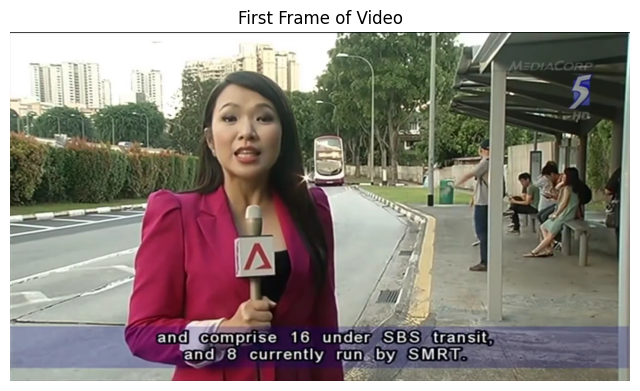

In [32]:
#displaying the sample video 
# Open the video
cap = cv2.VideoCapture(sample_path)

# Read the first frame
ret, frame = cap.read()

# Release the video
cap.release()

if ret:
    # Convert BGR to RGB for correct colours in Matplotlib
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Display the frame
    plt.figure(figsize=(8, 6))
    plt.imshow(frame_rgb)
    plt.title("First Frame of Video")
    plt.axis("off")
    plt.show()
else:
    print("Could not read the video.")


In [33]:
#Implementing the POS algorithm (Plane-Orthogonal-to-Skin)
#POS combines changes in the RGB channels to reduce some lighting effects and emphasize pulse-related color variations.
#Reduce lighting and skin-color effects to isolate pulse-related changes

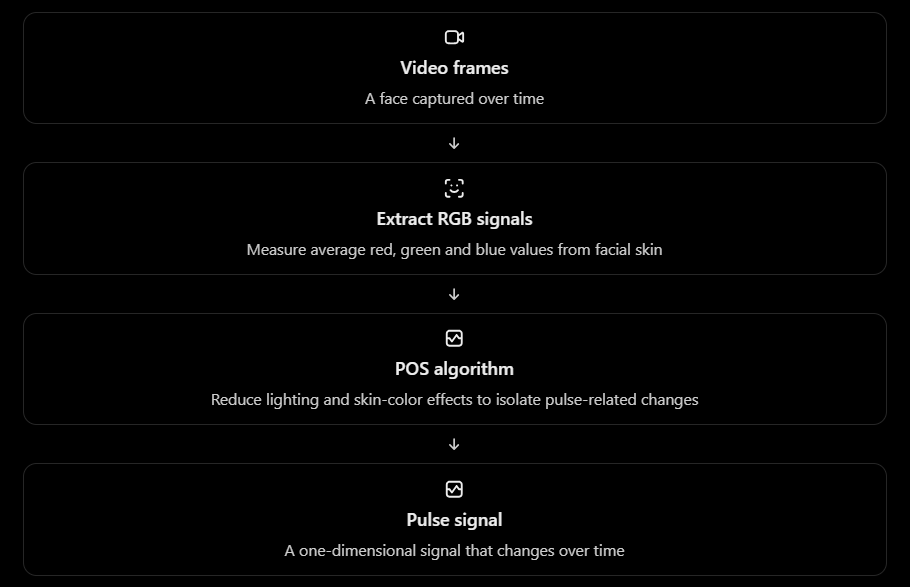
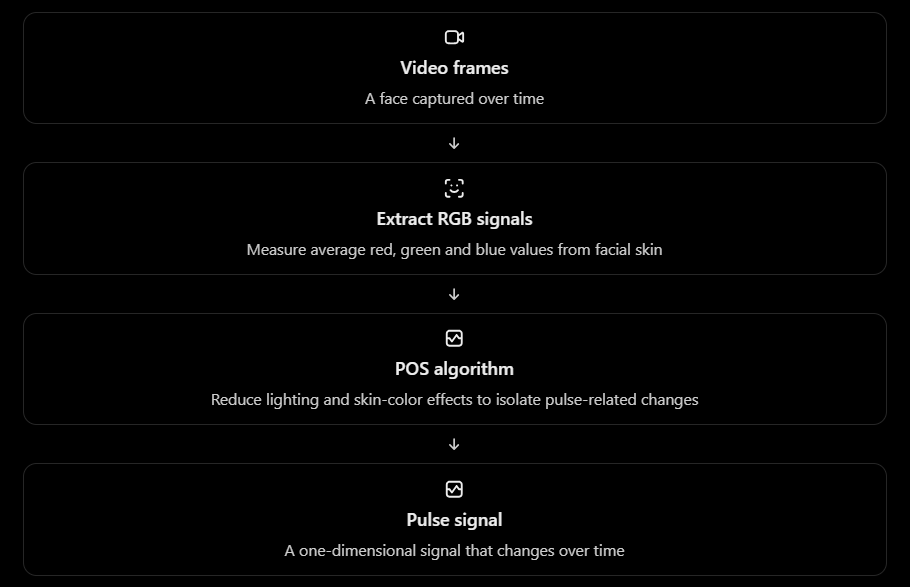
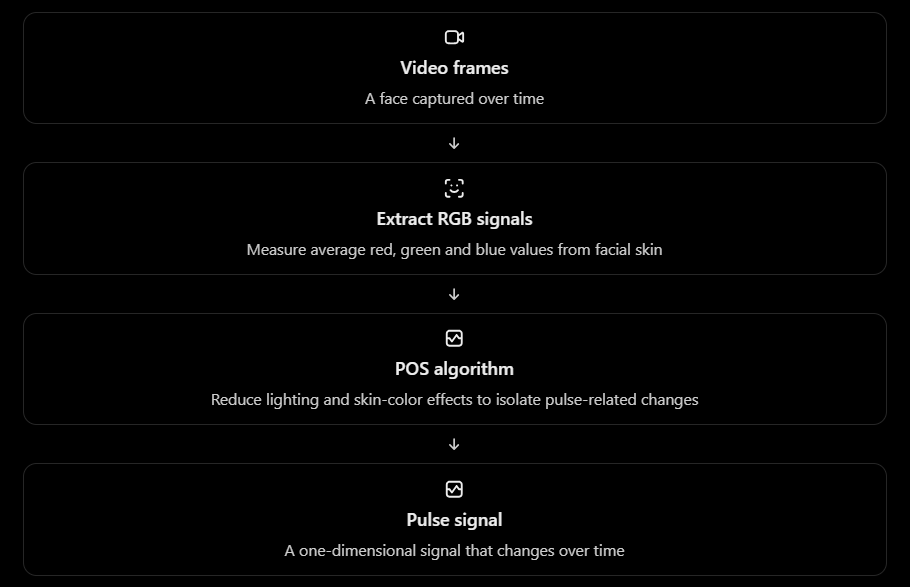

In [34]:
import numpy as np

def pos_rppg(rgb_signals, fps, window_seconds=1.6):
    """
    Estimate a pulse-related signal from RGB measurements.

    rgb_signals: array of shape (frames, 3), in RGB order.
    fps: effective sampling rate of these RGB measurements.
    """
    rgb = np.asarray(rgb_signals, dtype=np.float64)

    if rgb.ndim != 2 or rgb.shape[1] != 3:
        raise ValueError("Expected RGB data with shape (N, 3).") #N: no of video frames, 3: channels

    if len(rgb) < 30 or fps <= 0:
        return None

    # Normalize each channel by its local mean, we use window
    window = max(2, int(window_seconds * fps))
    pulse = np.zeros(len(rgb), dtype=np.float64)
    weights = np.zeros(len(rgb), dtype=np.float64)

    for start in range(0, len(rgb), max(1, window // 2)):
        end = min(len(rgb), start + window)

        segment = rgb[start:end]
        if len(segment) < max(10, int(fps)):
            continue

        mean_rgb = segment.mean(axis=0)
        if np.any(mean_rgb <= 0):
            continue

        normalized = segment / mean_rgb - 1.0

        #Instead of working with the original brightness values, the algorithm now works with relative changes around the local mean.

        # POS projection.
        #Because the pulse-related variation is mixed with other effects in every individual channel. 
        #Carefully chosen combinations can suppress some common skin-color and illumination effects while preserving useful pulse information.
        s1 = normalized[:, 1] - normalized[:, 2]
        s2 = (
            normalized[:, 1]
            + normalized[:, 2]
            - 2.0 * normalized[:, 0]
        )

        std_s1 = np.std(s1)
        std_s2 = np.std(s2)
        #std is propotional to variation

        if std_s2 < 1e-8: #If s2 barely varies, the code skips the window to avoid an unstable division.
            continue

        h = s1 + (std_s1 / (std_s2 + 1e-8)) * s2 #combining s1 n s2 : s1+ scaling factor*s2
        h = h - h.mean() #mean centering #The pattern of changes is preserved, but the average is now zero.

        pulse[start:end] += h
        weights[start:end] += 1

    valid = weights > 0 #frames that received at least one estimate [T,F]
    if valid.sum() < 30:
        return None

    pulse[valid] /= weights[valid] #algorithm averages overlapping estimates #pulse[valid] returns only values that are T
    pulse[~valid] = 0

    return pulse

In [35]:
#apply POS on a sample video
timestamps, rgb = extract_rgb_signals(sample_path)

if rgb is not None and len(timestamps) > 1:
    effective_fps = 1.0 / np.median(np.diff(timestamps))
    #Because some frames might not have a detected face, creating unusually large gaps. 
    #The median helps estimate the typical interval without being overly affected by those gaps.

    pulse_signal = pos_rppg(
        rgb,
        fps=effective_fps
    )

    print("Effective FPS:", round(effective_fps, 2))

    if pulse_signal is not None:
        print("Pulse signal length:", len(pulse_signal))
        print("First 10 values:", pulse_signal[:10])
    else:
        print("Pulse extraction failed. Try another video.")
else:
    print("RGB extraction failed. Try another video.")

W0000 00:00:1795069978.125148     271 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Effective FPS: 8.33
Pulse signal length: 154
First 10 values: [ 6.52761388e-03 -5.08634424e-05  3.51584455e-03  1.54946154e-03
  3.93187817e-03 -4.96008508e-03  4.48314311e-03 -4.75652944e-03
  6.15953531e-03 -2.85961532e-03]


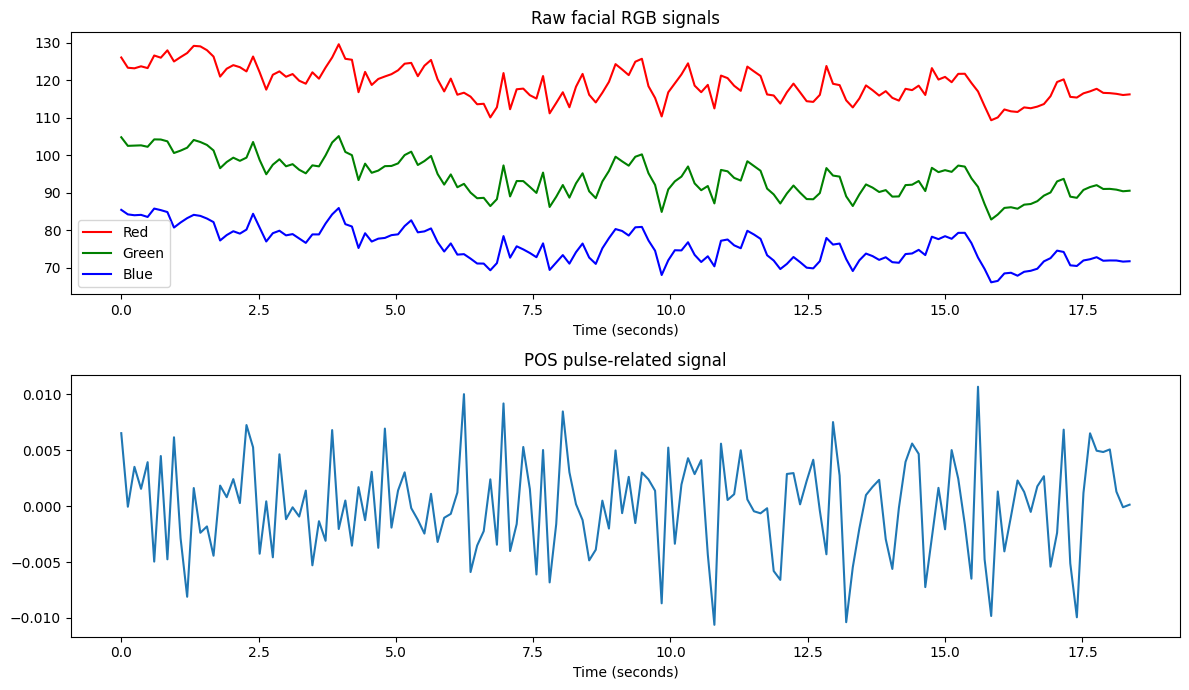

In [36]:
#plot the signals 
import matplotlib.pyplot as plt

if rgb is not None and pulse_signal is not None:
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))

    axes[0].plot(timestamps, rgb[:, 0], label="Red",c="r")
    axes[0].plot(timestamps, rgb[:, 1], label="Green",c="g")
    axes[0].plot(timestamps, rgb[:, 2], label="Blue",c="b")
    axes[0].set_title("Raw facial RGB signals")
    axes[0].set_xlabel("Time (seconds)")
    axes[0].legend()

    axes[1].plot(timestamps, pulse_signal)
    axes[1].set_title("POS pulse-related signal")
    axes[1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()

#Raw facial RGB signal 

alll channels seems to move together
note:there are pixel intensity values

#POS pulse-related signal 
-osilating around 0

-The signal has numerous peaks and troughs, but they don't immediately form an obvious, consistently repeating pattern. That may indicate noise, movement, weak pulse information, or a combination.

In [37]:
#applying POS on a fake sample video (face2face modification of the og vid)
fake_sample_path="/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/Face2Face/001_870.mp4"

timestamps, rgb = extract_rgb_signals(fake_sample_path)

if rgb is not None and len(timestamps) > 1:
    effective_fps = 1.0 / np.median(np.diff(timestamps))
    #Because some frames might not have a detected face, creating unusually large gaps. 
    #The median helps estimate the typical interval without being overly affected by those gaps.

    pulse_signal = pos_rppg(
        rgb,
        fps=effective_fps
    )

    print("Effective FPS:", round(effective_fps, 2))

    if pulse_signal is not None:
        print("Pulse signal length:", len(pulse_signal))
        print("First 10 values:", pulse_signal[:10])
    else:
        print("Pulse extraction failed. Try another video.")
else:
    print("RGB extraction failed. Try another video.")

W0000 00:00:1795069982.521878     284 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Effective FPS: 8.33
Pulse signal length: 202
First 10 values: [ 9.20382264e-03  2.16219882e-03  1.40513110e-03 -1.08075655e-03
  3.50617596e-03 -5.49870972e-03  4.06619391e-03 -4.85051234e-03
  6.72362131e-03  1.53408962e-05]


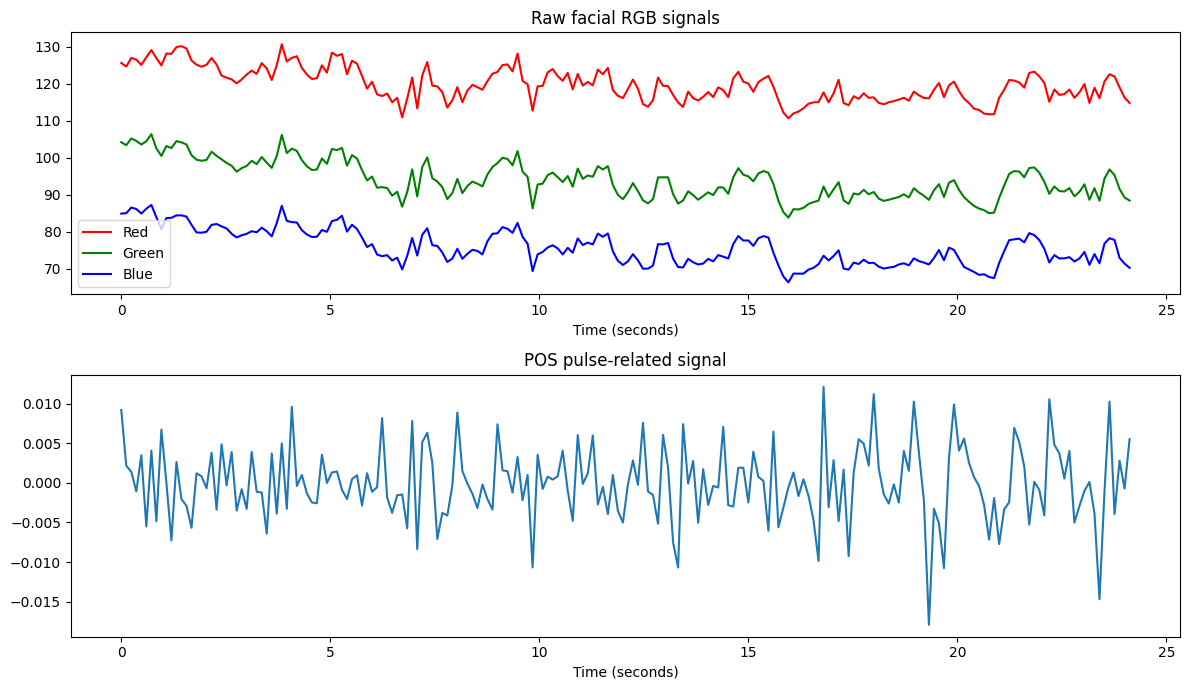

In [38]:
#plot the signals FACE2FACE
import matplotlib.pyplot as plt

if rgb is not None and pulse_signal is not None:
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))

    axes[0].plot(timestamps, rgb[:, 0], label="Red",c="r")
    axes[0].plot(timestamps, rgb[:, 1], label="Green",c="g")
    axes[0].plot(timestamps, rgb[:, 2], label="Blue",c="b")
    axes[0].set_title("Raw facial RGB signals")
    axes[0].set_xlabel("Time (seconds)")
    axes[0].legend()

    axes[1].plot(timestamps, pulse_signal)
    axes[1].set_title("POS pulse-related signal")
    axes[1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()

Raw facial RGB signal
- All channels seem to move together.
- Note: These are pixel intensity values averaged across the detected face region.
- Red has the highest intensity, followed by green and blue.
- All three channels show gradual fluctuations, with noticeable drops around 7–8 seconds, 15–16 seconds, and 20–21 seconds.
- These simultaneous changes may indicate common effects such as lighting variations, facial movement, or changes in the detected face region.
- Small variations may contain pulse-related information, but the raw signals alone do not reveal a clear heartbeat pattern.
- 
##POS pulse-related signal
- Oscillating around 0.
- The signal has numerous peaks and troughs, but they don't immediately form an obvious, consistently repeating pattern. That may indicate noise, movement, weak pulse information, or a combination.
- Several sharp peaks and drops are visible, particularly around 13–14 seconds and 19–20 seconds.
- These irregular fluctuations could reflect noise or imperfect separation of pulse-related changes from other facial variations.
- A stable heartbeat rhythm cannot be confidently identified visually from this plot alone.
  
Overall insight: This is a Face2Face-manipulated video, but its signals alone do not establish whether it is fake. The next step is to filter the POS signal and examine its frequency spectrum to determine whether a dominant, repeating pulse-related pattern exists.

In [39]:
#filter out frequencies outside human pulse range 
#use a bandpass filter of 0.7–3 Hz, corresponding approximately to 42–180 beats per minute
from scipy.signal import butter, sosfiltfilt

def filter_pulse_signal(pulse_signal, fps):
    low = 0.7
    high = 3.0

    if high >= fps / 2:
        raise ValueError("Sampling rate is too low for this filter.")

    sos = butter(
        3,
        [low, high],
        btype="bandpass",
        fs=fps,
        output="sos"
    )

    filtered = sosfiltfilt(sos, pulse_signal)

    return filtered

In [40]:
filtered_signal = filter_pulse_signal(
    pulse_signal,
    effective_fps
)

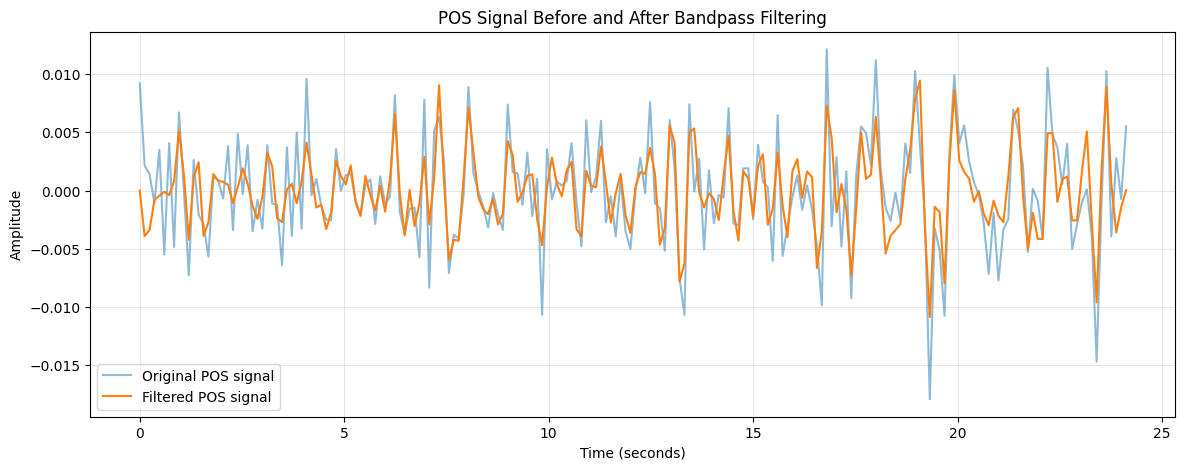

In [41]:
#plot the filtered graph 
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    timestamps,
    pulse_signal,
    label="Original POS signal",
    alpha=0.5
)

plt.plot(
    timestamps,
    filtered_signal,
    label="Filtered POS signal"
)

plt.title("POS Signal Before and After Bandpass Filtering")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
#feature extraction function
import numpy as np
from scipy.signal import welch, find_peaks
from scipy.stats import skew, kurtosis

def extract_features(pulse, fps):

    pulse = np.asarray(pulse, dtype=float)

    features = {}

    if len(pulse) < 30 or not np.all(np.isfinite(pulse)):
        return None

    # 1. Basic statistical features
    features["mean"] = np.mean(pulse)
    features["std"] = np.std(pulse)
    features["variance"] = np.var(pulse)
    features["skewness"] = skew(pulse)
    features["kurtosis"] = kurtosis(pulse)
    features["rms"] = np.sqrt(np.mean(pulse ** 2))

    # 2. Frequency-domain features
    frequencies, power = welch(
        pulse,
        fs=fps,
        nperseg=min(len(pulse), 128)
    )

    pulse_range = (
        (frequencies >= 0.7) &
        (frequencies <= 3.0)
    )

    f = frequencies[pulse_range]
    p = power[pulse_range]

    if len(p) == 0 or np.sum(p) <= 0:
        return None

    dominant_frequency = f[np.argmax(p)]

    features["dominant_frequency"] = dominant_frequency
    features["estimated_bpm"] = dominant_frequency * 60
    features["total_power"] = np.sum(p)
    features["peak_power"] = np.max(p)

    normalized_power = p / (np.sum(p) + 1e-12)

    features["spectral_entropy"] = -np.sum(
        normalized_power * np.log2(normalized_power + 1e-12)
    )

    features["spectral_flatness"] = (
        np.exp(np.mean(np.log(p + 1e-12))) /
        (np.mean(p) + 1e-12)
    )

    # 3. Peak-related features
    peaks, _ = find_peaks(pulse, distance=max(1, int(fps * 0.33)))

    features["peak_count"] = len(peaks)
    features["peak_rate"] = len(peaks) / (len(pulse) / fps)

    # 4. Autocorrelation / periodicity
    centered = pulse - np.mean(pulse)

    autocorr = np.correlate(
        centered, centered, mode="full"
    )[len(centered)-1:]

    autocorr = autocorr / (autocorr[0] + 1e-12)

    min_lag = max(1, int(fps / 3.0))
    max_lag = min(len(autocorr) - 1, int(fps / 0.7))

    if max_lag > min_lag:
        features["max_autocorrelation"] = np.max(
            autocorr[min_lag:max_lag + 1]
        )
    else:
        features["max_autocorrelation"] = 0

    return features

In [43]:
sample_features = extract_features(
    filtered_signal,
    effective_fps
)

for feature, value in sample_features.items():
    print(f"{feature}: {value:.5f}")

mean: -0.00004
std: 0.00339
variance: 0.00001
skewness: 0.15187
kurtosis: 0.68894
rms: 0.00339
dominant_frequency: 2.34375
estimated_bpm: 140.62500
total_power: 0.00017
peak_power: 0.00001
spectral_entropy: 4.83988
spectral_flatness: 0.76685
peak_count: 53.00000
peak_rate: 2.18647
max_autocorrelation: 0.15318


In [44]:
#video frame extraction func
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

def process_video(row, split_name):

    video_path = os.path.join(
        DATASET_PATH,
        row["File Path"]
    )

    try:
        # 1. Extract RGB signals
        timestamps, rgb = extract_rgb_signals(
            video_path,
            sample_every=3
        )

        if rgb is None or len(timestamps) < 30:
            return None

        # 2. Calculate effective FPS
        effective_fps = 1.0 / np.median(
            np.diff(timestamps)
        )

        # 3. Apply POS
        pulse = pos_rppg(
            rgb,
            effective_fps
        )

        if pulse is None:
            return None

        # 4. Bandpass filter
        filtered = filter_pulse_signal(
            pulse,
            effective_fps
        )

        # 5. Extract features
        features = extract_features(
            filtered,
            effective_fps
        )

        if features is None:
            return None

        # 6. Attach metadata
        features["File Path"] = row["File Path"]
        features["label"] = row["label"]
        features["Label"] = row["Label"]
        features["source_group"] = row["source_group"]
        features["split"] = split_name

        return features

    except Exception as e:
        return None

In [48]:
def process_split(df, split_name, limit_per_class=5):

    results = []

    # Select equal numbers of REAL and FAKE videos
    sample_df = (
        df.groupby("Label", group_keys=False)
          .apply(
              lambda x: x.sample(
                  n=min(limit_per_class, len(x)),
                  random_state=42
              )
          )
          .reset_index(drop=True)
    )

    for _, row in tqdm(
        sample_df.iterrows(),
        total=len(sample_df),
        desc=f"Processing {split_name}"
    ):


        
        result = process_video(row, split_name)

        if result is not None:
            results.append(result)

    return pd.DataFrame(results)


train_features = process_split(train_df, "train")
val_features = process_split(val_df, "validation")
test_features = process_split(test_df, "test")

/tmp/ipykernel_49/4175829281.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Processing train:   0%|          | 0/10 [00:00<?, ?it/s]

W0000 00:00:1795070024.897145     348 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070027.939553     362 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070030.708217     376 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070032.318943     388 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070035.378824     402 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070038.213465     413 inference_feedback_manager.cc:114] Feedback manager 

Processing validation:   0%|          | 0/10 [00:00<?, ?it/s]

W0000 00:00:1795070061.950481     478 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070065.611750     492 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070069.064421     505 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070070.652344     519 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070073.983923     532 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070075.908683     543 inference_feedback_manager.cc:114] Feedback manager 

Processing test:   0%|          | 0/10 [00:00<?, ?it/s]

W0000 00:00:1795070091.401058     610 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070093.165558     623 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070095.890451     635 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070097.493470     648 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070099.448904     661 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795070102.618884     674 inference_feedback_manager.cc:114] Feedback manager 

In [49]:
print("Train:", train_features.shape)
print("Validation:", val_features.shape)
print("Test:", test_features.shape)

print("\nTraining labels:")
print(train_features["Label"].value_counts())

print("\nExtracted feature table:")
display(train_features.head())

Train: (9, 20)
Validation: (10, 20)
Test: (9, 20)

Training labels:
Label
FAKE    5
REAL    4
Name: count, dtype: int64

Extracted feature table:


,mean,std,variance,skewness,kurtosis,rms,dominant_frequency,estimated_bpm,total_power,peak_power,spectral_entropy,spectral_flatness,peak_count,peak_rate,max_autocorrelation,File Path,label,Label,source_group,split
0,-0.000106,0.004684,0.000022,-0.118415,0.423804,0.004685,2.048023,122.881356,0.000284,0.000029,4.567548,0.657121,26,1.836158,0.142926,FaceShifter/375_251.mp4,1,FAKE,group_157,train
1,-0.000082,0.003051,0.000009,0.136515,0.063646,0.003052,2.414330,144.859813,0.000097,0.000012,4.423555,0.654205,26,2.024922,0.144469,FaceSwap/520_542.mp4,1,FAKE,group_295,train
2,0.000043,0.008628,0.000074,-0.362399,0.475032,0.008628,1.051780,63.106796,0.000968,0.000112,4.338458,0.578740,29,2.346278,0.312321,FaceSwap/205_184.mp4,1,FAKE,group_124,train
3,-0.000130,0.002720,0.000007,-0.693006,2.357524,0.002724,2.454545,147.272727,0.000062,0.000016,3.598027,0.458229,25,2.272727,0.274718,FaceShifter/778_798.mp4,1,FAKE,group_422,train
4,-0.000016,0.007409,0.000055,-0.397149,1.809225,0.007409,1.093750,65.625000,0.000719,0.000093,4.357180,0.628455,43,2.128713,0.248048,Deepfakes/452_550.mp4,1,FAKE,group_266,train


In [50]:
for name, df in [
    ("TRAIN", train_features),
    ("VALIDATION", val_features),
    ("TEST", test_features)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print(df["Label"].value_counts())


TRAIN
Shape: (9, 20)
Label
FAKE    5
REAL    4
Name: count, dtype: int64

VALIDATION
Shape: (10, 20)
Label
FAKE    5
REAL    5
Name: count, dtype: int64

TEST
Shape: (9, 20)
Label
FAKE    5
REAL    4
Name: count, dtype: int64


In [51]:
#full feature extraction function
#Since this involves thousands of videos, we'll save the extracted features so that a Kaggle interruption doesn't force us to start from scratch.def extract_dataset_features(df, split_name, checkpoint_file):

def extract_dataset_features(df, split_name, checkpoint_file):

    results = []

    for i, (_, row) in enumerate(
        tqdm(df.iterrows(), total=len(df), desc=split_name)
    ):

        result = process_video(row, split_name)

        if result is not None:
            results.append(result)

        # Save progress every 100 videos
        if (i + 1) % 100 == 0:
            pd.DataFrame(results).to_csv(
                checkpoint_file,
                index=False
            )

    features_df = pd.DataFrame(results)

    features_df.to_csv(
        checkpoint_file,
        index=False
    )

    return features_df

In [ ]:
train_features = extract_dataset_features(
    train_df,
    "train",
    "/kaggle/working/train_features.csv"
)

In [ ]:
val_features = extract_dataset_features(
    val_df,
    "validation",
    "/kaggle/working/val_features.csv"
)

In [ ]:
test_features = extract_dataset_features(
    test_df,
    "test",
    "/kaggle/working/test_features.csv"
)

In [61]:
FEATURE_PATH = "/kaggle/input/datasets/nadantikaap/features"

train_features = pd.read_csv(
    f"{FEATURE_PATH}/train_features.csv"
)

val_features = pd.read_csv(
    f"{FEATURE_PATH}/val_features.csv"
)

test_features = pd.read_csv(
    f"{FEATURE_PATH}/test_features.csv"
)

In [62]:
#prepare feature value
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import numpy as np
import pandas as pd

# Columns that should NOT be used for training
exclude_columns = [
    "File Path",
    "Label",
    "label",
    "source_group",
    "split"
]

feature_columns = [
    col for col in train_features.select_dtypes(
        include=np.number
    ).columns
    if col not in exclude_columns
]

X_train = train_features[feature_columns]
y_train = train_features["label"]

X_val = val_features[feature_columns]
y_val = val_features["label"]

X_test = test_features[feature_columns]
y_test = test_features["label"]

print("Number of features:", len(feature_columns))
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Number of features: 15
Training samples: 4102
Validation samples: 891
Testing samples: 883


In [63]:
#hadle missing values 
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=feature_columns
)

X_val = pd.DataFrame(
    imputer.transform(X_val),
    columns=feature_columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=feature_columns
)

In [64]:
#initializing n traning random forest 
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# ACTUAL MODEL TRAINING
model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [65]:
#evaluate on validate data
y_val_pred = model.predict(X_val)
y_val_prob = model.predict_proba(X_val)[:, 1]

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["REAL", "FAKE"]
))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation Accuracy: 0.8327721661054994

Classification Report:
              precision    recall  f1-score   support

        REAL       0.33      0.01      0.01       148
        FAKE       0.83      1.00      0.91       743

    accuracy                           0.83       891
   macro avg       0.58      0.50      0.46       891
weighted avg       0.75      0.83      0.76       891

ROC-AUC: 0.5734967807646139

Confusion Matrix:
[[  1 147]
 [  2 741]]


In [66]:
#low accuracy 
#check traininng class distribution
print("Training distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nFeature columns:")
print(feature_columns)

Training distribution:
label
1    3419
0     683
Name: count, dtype: int64

Validation distribution:
label
1    743
0    148
Name: count, dtype: int64

Feature columns:
['mean', 'std', 'variance', 'skewness', 'kurtosis', 'rms', 'dominant_frequency', 'estimated_bpm', 'total_power', 'peak_power', 'spectral_entropy', 'spectral_flatness', 'peak_count', 'peak_rate', 'max_autocorrelation']


In [67]:
#checking if mmodel is predicting fake for almost everything
predictions = model.predict(X_val)

print("Prediction distribution:")
print(pd.Series(predictions).value_counts())

print("\nPrediction probabilities:")
print(
    pd.DataFrame({
        "Actual": y_val.reset_index(drop=True),
        "Predicted": predictions,
        "REAL_probability": model.predict_proba(X_val)[:, 0],
        "FAKE_probability": model.predict_proba(X_val)[:, 1]
    }).head(15)
)

Prediction distribution:
1    888
0      3
Name: count, dtype: int64

Prediction probabilities:
    Actual  Predicted  REAL_probability  FAKE_probability
0        0          1          0.260316          0.739684
1        0          1          0.247628          0.752372
2        0          1          0.441558          0.558442
3        0          1          0.126730          0.873270
4        0          1          0.189027          0.810973
5        0          1          0.321731          0.678269
6        0          1          0.252866          0.747134
7        0          1          0.130983          0.869017
8        0          1          0.352233          0.647767
9        0          1          0.082155          0.917845
10       0          1          0.159484          0.840516
11       0          1          0.169905          0.830095
12       0          1          0.139413          0.860587
13       0          1          0.203126          0.796874
14       0          1          0.2

In [68]:
#comparinf feature distrcibution between REAL and FAKE
comparison = train_features.groupby("Label")[
    feature_columns
].mean().T

display(comparison)

Label,FAKE,REAL
mean,-0.000031,-0.000024
std,0.004394,0.004183
variance,0.000031,0.000033
skewness,-0.023881,-0.013533
kurtosis,0.793956,0.781193
rms,0.004395,0.004184
dominant_frequency,1.561059,1.529322
estimated_bpm,93.663527,91.759333
total_power,0.000348,0.000304
peak_power,0.000050,0.000041


In [69]:
#checking whether the model's decision threshold is contributing to the problem
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

y_val_prob = model.predict_proba(X_val)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    predictions = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Accuracy:",
          accuracy_score(y_val, predictions))

    print("Balanced Accuracy:",
          balanced_accuracy_score(y_val, predictions))

    print("REAL Recall:",
          recall_score(y_val, predictions, pos_label=0))

    print("FAKE Recall:",
          recall_score(y_val, predictions, pos_label=1))

    print("Macro F1:",
          f1_score(y_val, predictions, average="macro"))


Threshold: 0.3
Accuracy: 0.8338945005611672
Balanced Accuracy: 0.5
REAL Recall: 0.0
FAKE Recall: 1.0
Macro F1: 0.45471236230110157

Threshold: 0.4
Accuracy: 0.8338945005611672
Balanced Accuracy: 0.5
REAL Recall: 0.0
FAKE Recall: 1.0
Macro F1: 0.45471236230110157

Threshold: 0.5
Accuracy: 0.8327721661054994
Balanced Accuracy: 0.50203248335819
REAL Recall: 0.006756756756756757
FAKE Recall: 0.9973082099596231
Macro F1: 0.46094501808909333

Threshold: 0.6
Accuracy: 0.8271604938271605
Balanced Accuracy: 0.5149003310174239
REAL Recall: 0.0472972972972973
FAKE Recall: 0.9825033647375505
Macro F1: 0.49395910780669144

Threshold: 0.7
Accuracy: 0.7755331088664422
Balanced Accuracy: 0.5488750863919101
REAL Recall: 0.20945945945945946
FAKE Recall: 0.8882907133243607
Macro F1: 0.5525311370028124


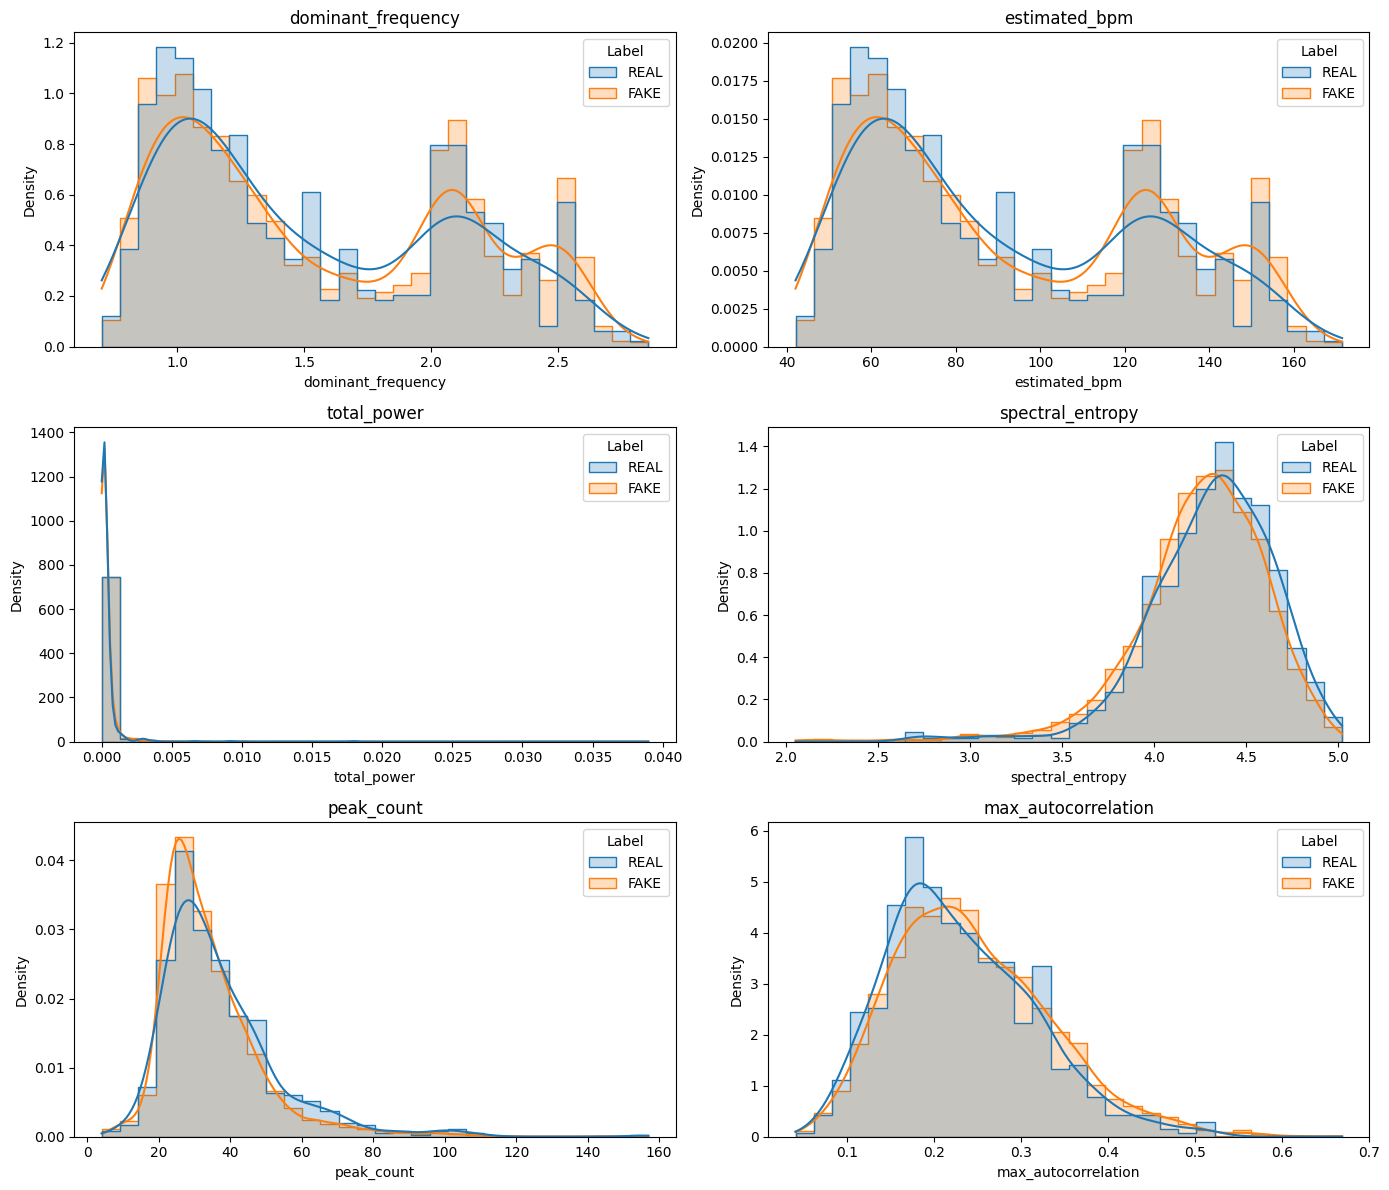

In [70]:
#visualize feature distribution
import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = [
    "dominant_frequency",
    "estimated_bpm",
    "total_power",
    "spectral_entropy",
    "peak_count",
    "max_autocorrelation"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for feature, ax in zip(features_to_plot, axes.flatten()):

    sns.histplot(
        data=train_features,
        x=feature,
        hue="Label",
        bins=30,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()

## Conclusion

This experiment explored the potential of remote photoplethysmography (rPPG) as an approach to deepfake detection by analysing subtle physiological variations in facial videos. Facial RGB signals were extracted using MediaPipe and OpenCV, processed using the POS algorithm, and analysed through frequency-domain and statistical feature extraction. These features were then used to train a Random Forest classifier on the FaceForensics++ C23 dataset.

The initial results revealed significant overlap between the extracted features of real and manipulated videos. Although the model achieved 83.28% validation accuracy, its balanced accuracy was only 50.20%, with a ROC-AUC of approximately 0.573. The model struggled particularly with identifying genuine videos, indicating that the extracted whole-face rPPG features did not provide sufficient discriminatory information in their current form.

Despite the limited classification performance, the experiment provided valuable insights into the challenges of extracting physiological information from compressed and manipulated facial videos. It established a baseline for evaluating heartbeat-related features independently and highlighted the need for more robust signal extraction and temporal analysis.

Further work will investigate region-specific facial signal extraction, particularly from the forehead and cheeks, to determine whether localized physiological information can improve detection. Ultimately, this research aims to explore the integration of physiological signals with visual deepfake detection to develop a more comprehensive hybrid detection framework.